In [1]:
import pandas as pd
import numpy as np
#from lm_polygraph.generation_metrics import AlignScore

In [2]:
def calc_lengths(dat, tokenizer):
    def tokenize(question, context, answer):
        answer = str(answer)
        messages = [
            {"role": "user", "content": f"Question:\n{question}\nContext:\n{context}\n"},
            {"role": "assistant", "content": f"Answer:\n{answer}\n"},
        ]
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=False
        )
        return len(text)
    lengths = []
    for idx in range(len(dat)):
        toks = tokenize(dat["question"].loc[idx], dat["context"].loc[idx], dat["target"].loc[idx])
        lengths.append(toks)
    return lengths    

In [3]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("google/gemma-3-1b-it")

/home/jovyan/gkuzmin/llm_ue/conda_llm_ue_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def calc_em_cuad(targets, preds, is_mamba=False, is_deltanet=False, is_filtered=False):
    exact_match = []
    for target, pred in zip(targets, preds):
        try:
            parsed_pred = pred.split("Answer:\n")[1]
            parsed_pred = parsed_pred.split("\n")[0]
        except:
            parsed_pred = pred
        if is_mamba:
            try:
                parsed_pred = pred.split("Answer:\n")[1]
                parsed_pred = parsed_pred.split("<|")[0]
            except:
                parsed_pred = pred
        if is_deltanet:
            try:
                parsed_pred = pred.split("Answer:\n")[1]
                parsed_pred = parsed_pred.split(" ")[0]
            except:
                parsed_pred = pred
        if is_filtered:
            parsed_pred = pred
        exact_match.append(int(str(target).strip() == str(parsed_pred).strip()))
    return exact_match

In [5]:
def calc_alignscore(targets, preds, scorer):
    filtered_preds = []
    for pred in preds:
        try:
            parsed_pred = pred.split("Answer:\n")[1]
            parsed_pred = parsed_pred.split("\n")[0]
        except:
            parsed_pred = pred
        filtered_preds.append(str(parsed_pred))
    scores = scorer({"greedy_texts": filtered_preds}, [str(el) for el in targets])
    return scores

## Now load results after merge

In [6]:
# load and process additional res
add_fnames = [
    
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-9700/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    # gemma3-1b left pad assist mask es 15 no sw, from 2s
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-7000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_10000/checkpoint-4000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-4700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/from_new_pretrain_old_impl_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_10000/checkpoint-7100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/from_new_pretrain_old_impl_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_3e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_no_cl_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10000/checkpoint-9700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/google/gemma-3-1b-it/top_N_assoc_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-7100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/google/gemma-3-1b-it/top_N_assoc_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_1e-04_10000/checkpoint-4500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/top_N_assoc_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_3e-05_10000/checkpoint-5100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",



    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/evals-128k/qa_evals_mt_0k_128k_600_v2-mamba2-mnt256/AntonV/mamba2-1.3b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/AntonV/mamba2-1.3b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x4096_4096_64_1e-04_10000/checkpoint-6600/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/evals-128k/qa_evals_mt_0k_128k_600_v2-mamba-mnt256/state-spaces/mamba-1.4b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/state-spaces/mamba-1.4b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_3e-04_10000-v2.1/checkpoint-6600/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/evals-128k/qa_evals_mt_0k_128k_600_v2-deltanet-3e-04-mnt256/fla-hub/delta_net-1.3B-100B/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/fla-hub/delta_net-1.3B-100B/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000-v2.2/checkpoint-6200/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_mt_0k_128k_600_v2_xlstm_stage3/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/manytypes_v2_flat_stacked_no_empty_sv_0k_8k_val_16k/NX-AI/xlstm_scaling_laws/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_ctx_7936_3e-5_10000/run_37/checkpoint-900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_mt_0k_128k_600_v2_xlstm_stage3/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/manytypes_v2_flat_stacked_no_empty_sv_0k_8k_val_16k/NX-AI/xlstm_scaling_laws/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_ctx_7936_3e-5_10000/run_37/checkpoint-900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_trunc_cont_8192.csv",

    
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_mt_0k_128k_600_v2-fixed/AntonV/mamba2-1.3b-hf/workspace-SR006.nfs2/bulatov/rmt/llm-armt/armt-instruct-tune/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/AntonV/mamba2-1.3b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x4096_4096_64_1e-04_10000/checkpoint-6600/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_mt_0k_128k_600_v2-fixed/state-spaces/mamba-1.4b-hf/workspace-SR006.nfs2/bulatov/rmt/llm-armt/armt-instruct-tune/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/state-spaces/mamba-1.4b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_3e-04_10000-v2.1/checkpoint-6600/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_mt_0k_128k_600_v2-fixed/fla-hub/delta_net-1.3B-100B/workspace-SR006.nfs2/bulatov/rmt/llm-armt/armt-instruct-tune/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/fla-hub/delta_net-1.3B-100B/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000-v2.2/checkpoint-6200/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_mt_0k_128k_600_v2-fixed/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/manytypes_v2_flat_stacked_no_empty_sv_0k_8k_val_16k/NX-AI/xlstm_scaling_laws/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_ctx_7936_3e-5_10000/run_37/checkpoint-900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_mt_0k_128k_600_v2-fixed/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/manytypes_v2_flat_stacked_no_empty_sv_0k_8k_val_16k/NX-AI/xlstm_scaling_laws/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_ctx_7936_3e-5_10000/run_37/checkpoint-900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_trunc_cont_8192.csv",

]



add_mod_names = [
    "Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain-no-cl",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected",
    "Mamba-2-1.3B",
    "Mamba-1.4B",
    "DeltaNet-1.3B",
    "XLSTM",
    #"XLSTM, max 8k",
]


add_fnames = add_fnames[:]
add_mod_names = add_mod_names[:]
add_new_index = add_mod_names


In [7]:
dat = pd.read_csv(add_fnames[0])
for idx, fname in enumerate(add_fnames[1:]):
    buf_dat = pd.read_csv(fname)
    #dat[f"output_{idx}"] = buf_dat["output"]
    dat[add_mod_names[idx+1]] = buf_dat["output"]
dat = dat.rename({"output": add_mod_names[0]}, axis=1)

In [8]:
len(add_fnames), len(add_mod_names)

(15, 15)

In [9]:
# map results for xlstm models

In [10]:
dat

,Unnamed: 0,target,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift,question,context,time,mem_usage,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,...,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain-no-cl,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected,Mamba-2-1.3B,Mamba-1.4B,DeltaNet-1.3B,XLSTM
0,0,typing.Any,Answer:\ntyping.Any,What is the type of variable sociallogin?,"from typing import Tuple , Union \nimport typi...",0.722836,2878.0,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,...,Answer:\ntyping.Any,Answer:\ndjango.http.HttpRequest,Answer:\ntyping.Any,Answer:\ndjango.http.HttpRequest,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\nbuiltins.str acknowsionable acknowsio...,Answer:\ntyping.Any
1,1,builtins.bool,Answer:\nbuiltins.bool,What is the type of variable resets_positions?,"from typing import Any , Dict \nimport typing ...",0.361791,2872.0,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,...,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool,Answer:\nbuiltins.bool strugging.bool struggin...,Answer:\nbuiltins.bool
2,2,builtins.float,Answer:\ntyping.Any,What is the type of variable max_ram?,"from typing import Any , Dict , List \nimport ...",0.310744,2872.0,Answer:\ntyping.Any,Answer:\nbuiltins.float,Answer:\ntyping.Any,...,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\nbuiltins.int,Answer:\ntyping.Any,Answer:\nbuiltins.float,Answer:\nbuiltins.int,Answer:\nbuiltins.float,Answer:\nbuiltins.int acknowing the same value...,Answer:\ntyping.Any
3,3,builtins.str,Answer:\nbuiltins.str,What is the type of variable DATABASES_KEY?,[comment] \n[comment] \n[comment] \n[comment] ...,0.368701,2864.0,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,...,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str,Answer:\nbuiltins.str acknowsistant acknowsist...,Answer:\nbuiltins.str
4,4,typing.Any,Answer:\ntyping.Any,What is the type of variable total_expected_ra...,"from typing import Type , Any \nimport backend...",0.314765,2864.0,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,...,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\ntyping.Any,Answer:\nbuiltins.int acknowsioning the answer...,Answer:\ntyping.Any
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,1495,builtins.str,typing.Any,What is the type of variable data_key?,[docstring] \n\nrepos/smart-minds/home-api/hom...,2.594363,13526.0,know know know know know know know know know k...,Answer:\nbuiltins.str,Answer:\nbuiltins.str,...,োলোলোলোলোলোলোলোলোলোলোলোলোলোলোলোলোলোলোলোলোলোলোল...,Answer:\nbuiltins.str,Answer:\nbuiltins.str,s_key_key_s_key_s_key_s_key_s_key_s_key_s_key_...,builtbuiltbuiltbuiltbuiltbuiltbuiltbuiltbuil

In [11]:
list(dat.columns)

['Unnamed: 0',
 'target',
 'Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift',
 'question',
 'context',
 'time',
 'mem_usage',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain-no-cl',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_n

In [12]:
lens = calc_lengths(dat, tokenizer)

In [13]:
dat["lens"] = lens

In [14]:
#new_baseline_cols = list(new_baseline_res.columns[3:])
new_baseline_cols = []

In [15]:
mods = dat.columns[2:]
mods = [el for el in mods if el not in ['question', 'context', 'lens', 'time', 'mem_usage']]
scores = {}
scores_align = {}
for mod in mods:
    print(mod)
    mod_em = calc_em_cuad(dat["target"], dat[mod], is_mamba="mamba" in mod.lower(), is_deltanet="deltanet" in mod.lower(), is_filtered=mod in new_baseline_cols)
    #scores[mod] = mod_em
    dat[f"target_{mod}_em"] = mod_em
    mod_align = calc_em_cuad(dat["target"], dat[mod], is_mamba="mamba" in mod.lower(), is_deltanet="deltanet" in mod.lower(), is_filtered=mod in new_baseline_cols)#calc_alignscore(dat["target"], dat[mod], scorer)
    dat[f"target_{mod}_align"] = mod_align
print(scores)

Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain-no-cl
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-

In [16]:
mods

['Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain-no-cl',
 'ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected',
 'ARMT-Gemma3-1b-IT-

In [17]:
targ_cols_only = [el for el in dat.columns if (("_align" in el or "len" in el) and "_lens" not in el and "_usage" not in el)]
results_alignscore = {}
targs = dat[targ_cols_only]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*18, 1024*20, 32768]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*18, 1024*20, 32768, 65536]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48, 1024*64, 1024*96]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536, 1024*96, 1024*128]
for start, end in zip(starts, ends):
    buf_res = targs[(targs["lens"] > start) & (targs["lens"] < end)]
    print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_alignscore[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

0 1024 78
1024 2048 105
2048 4096 106
4096 6144 73
6144 8192 92
8192 10240 81
10240 12288 91
12288 14336 94
14336 16384 89
16384 24576 144
24576 32768 101
32768 49152 115
49152 65536 101
65536 98304 82
98304 131072 145


In [18]:
alignscores = pd.concat(results_alignscore, axis=1)
alignscores = alignscores.drop("lens")
alignscores.index = add_new_index# + list(new_baseline_res.columns)

In [19]:
support = []
for start, end in zip(starts, ends):
    buf_res = targs[(targs["lens"] > start) & (targs["lens"] < end)]
    support.append(len(buf_res))

In [20]:
support

[78, 105, 106, 73, 92, 81, 91, 94, 89, 144, 101, 115, 101, 82, 145]

In [21]:
support

[78, 105, 106, 73, 92, 81, 91, 94, 89, 144, 101, 115, 101, 82, 145]

In [22]:
targ_cols_only = [el for el in dat.columns if (("_em" in el or "len" in el) and "_lens" not in el and "_usage" not in el)]
results_em = {}
targs = dat[targ_cols_only]
starts = [0, 1024, 2048, 4096, 8192, 16384, 32768]
ends = [1024, 2048, 4096, 8192, 16384, 32768, 65536]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*18, 1024*20, 32768]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*18, 1024*20, 32768, 65536]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48, 1024*64, 1024*96]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536, 1024*96, 1024*128]
for start, end in zip(starts, ends):
    buf_res = targs[(targs["lens"] > start) & (targs["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_em[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [23]:
ems = pd.concat(results_em, axis=1)
ems = ems.drop("lens")
ems.index = add_new_index# + list(new_baseline_res.columns)

In [24]:
import copy

In [25]:
pd.set_option('display.max_colwidth', 100)
als = copy.deepcopy(alignscores)
emss = copy.deepcopy(ems)

In [26]:
als = als.reset_index()
als = als.rename({"index": "Model"}, axis=1)
emss = emss.reset_index()
emss = emss.rename({"index": "Model"}, axis=1)

In [27]:
als

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k,65k_98k,98k_131k
0,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift,0.794872,0.790476,0.773585,0.767123,0.858696,0.851852,0.868132,0.787234,0.764045,0.812500,0.712871,0.591304,0.316832,0.182927,0.262069
1,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.782051,0.723810,0.688679,0.616438,0.608696,0.506173,0.373626,0.404255,0.337079,0.229167,0.198020,0.139130,0.089109,0.048780,0.034483
2,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.769231,0.742857,0.707547,0.657534,0.793478,0.765432,0.659341,0.585106,0.595506,0.625000,0.465347,0.417391,0.405941,0.170732,0.248276
3,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.756410,0.742857,0.735849,0.698630,0.804348,0.753086,0.791209,0.744681,0.685393,0.756944,0.712871,0.765217,0.712871,0.573171,0.758621
4,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pa...,0.769231,0.752381,0.707547,0.671233,0.793478,0.753086,0.692308,0.744681,0.629213,0.631944,0.584158,0.530435,0.425743,0.378049,0.165517
5,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pa...,0.756410,0.742857,0.707547,0.671233,0.804348,0.790123,0.747253,0.734043,0.640449,0.638889,0.673267,0.608696,0.544554,0.512195,0.413793
6,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pa...,0.756410,0.742857,0.735849,0.739726,0.858696,0.827160,0.868132,0.765957,0.696629,0.756944,0.811881,0.791304,0.762376,0.646341,0.820690
7,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pa...,0.807692,0.771429,0.726415,0.726027,0.804348,0.851852,0.857143,0.765957,0.730337,0.798611,0.772277,0.817391,0.772277,0.731707,0.834483
8,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pa...,0.782051,0.723810,0.679245,0.397260,0.130435,0.012346,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pa...,0.756410,0.704762,0.716981,0.698630,0.815217,0.691358,0.747253,0.765957,0.584270,0.604167,0.435644,0.434783,0.485149,0.231707,0.227586


In [28]:
als.to_csv("mt_v2_res_em_0k_128k_bal_sup.csv")


In [29]:
#new_baseline_res = pd.read_csv("../qa_evals_mt_0k_64k_600_v2_bal_sup/baseline_results.csv")

In [30]:
#new_baseline_res

## Get time

In [170]:
def calc_ans_lengths(dat, col, tokenizer):
    def tokenize(answer):
        answer = str(answer)
        text = tokenizer(
            answer,
            add_special_tokens=False,
        )["input_ids"]
        return len(text)
    lengths = []
    for idx in range(len(dat)):
        toks = tokenize(dat[col].loc[idx])
        lengths.append(toks)
    return lengths    

In [171]:
time_fnames = [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs1.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs8.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs4.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs1.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs8.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs32.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs4.csv",
]
time_names = [
    "Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    "ARMT-Gemma-3-1B-IT-MT-8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]

In [172]:
# get times
time_res = {}
buf_fnames = time_fnames
buf_names = time_names
for path, name in zip(buf_fnames, buf_names):
    print(name)
    buf_df = pd.read_csv(path)
    print(len(buf_df))
    if path == buf_fnames[0]:
        time_res["question"] = buf_df["question"]
        time_res["context"] = buf_df["context"]
        time_res["target"] = buf_df["target"]
    time_res[f"{name}_time_base"] = buf_df["time"]
    time_res[f"{name}_answer"] = buf_df["output"]
    time_res[f"{name}_mem"] = buf_df["mem_usage"]
    time_res[f"{name}_ans_len"] = calc_ans_lengths(buf_df, "output", tokenizer)
    time_res[f"{name}_time"] = np.array(time_res[f"{name}_time_base"]) / np.array(time_res[f"{name}_ans_len"])
time_df = pd.DataFrame.from_dict(time_res)
time_df["lens"] = calc_lengths(time_df, tokenizer)

Gemma-3-1B-IT-MT-8k
1300
Gemma-3-1B-IT-MT-8k, batched-8
1300
ARMT-Gemma-3-1B-IT-MT-8k
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched-32
1300


In [173]:
time_cols_only_bal_sup = [el for el in time_df.columns if ((("_time" in el and "_rougeLsum" not in el) or "len" in el or "mem" in el) and "_lens" not in el)]
results_time_bal_sup = {}
targs_time = time_df[time_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_time[(targs_time["lens"] > start) & (targs_time["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_time_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [174]:
times_bal_sup = pd.concat(results_time_bal_sup, axis=1)
#times_bal_sup = times_bal_sup.drop("lens")
times_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma-3-1B-IT-MT-8k_time_base,0.450999,0.488075,0.434237,0.505705,0.472583,0.463664,0.469916,0.461620,0.451326,0.466876,0.786268,0.817895,8.410290
Gemma-3-1B-IT-MT-8k_mem,2858.615385,2928.057143,3062.849057,3253.726027,3429.804348,3627.950617,3782.747253,3949.000000,4161.303371,4465.180556,5372.772277,6296.104348,7919.900990
Gemma-3-1B-IT-MT-8k_ans_len,8.500000,9.619048,8.132075,9.410959,8.315217,7.617284,7.373626,6.914894,6.067416,5.673611,10.633663,8.826087,178.574257
Gemma-3-1B-IT-MT-8k_time,0.054294,0.052390,0.054674,0.055934,0.058811,0.062877,0.067172,0.074523,0.079621,0.090513,0.109381,0.145690,0.097586
"Gemma-3-1B-IT-MT-8k, batched-8_time_base",0.106152,0.132517,0.131111,0.141244,0.158974,0.172708,0.260506,0.249818,0.227295,0.359710,0.429209,1.247749,2.057637
"Gemma-3-1B-IT-MT-8k, batched-8_mem",3642.846154,4201.733333,5535.018868,7246.493151,8836.130435,10210.740741,11458.549451,12934.978723,14543.483146,17830.208333,25486.099010,36449.843478,46413.683168
"Gemma-3-1B-IT-MT-8k, batched-8_ans_len",8.500000,9.619048,8.132075,8.863014,8.315217,7.617284,7.373626,9.234043,6.067416,5.715278,10.663366,8.704348,181.099010
"Gemma-3-1B-IT-MT-8k, batched-8_time",0.014170,0.017364,0.018499,0.018710,0.021744,0.025145,0.045415,0.041524,0.044143,0.080291,0.082543,0.289256,0.165488
ARMT-Gemma-3-1B-IT-MT-8k_time_base,0.488417,0.512979,0.543668,0.721658,0.795370,0.864982,1.004172,1.145314,1.234691,1.434877,2.327127,2.682487,3.754238
ARMT-Gemma-3-1B-IT-MT-8k_mem,3158.692308,3722.000000,4224.528302,4224.410959,4224.739130,4224.098765,4224.263736,4224.680851,4224.494382,4224.736111,4224.455446,4224.591304,4224.039604


In [175]:
x=1

In [176]:
import matplotlib.pyplot as plt
import matplotlib as mpl


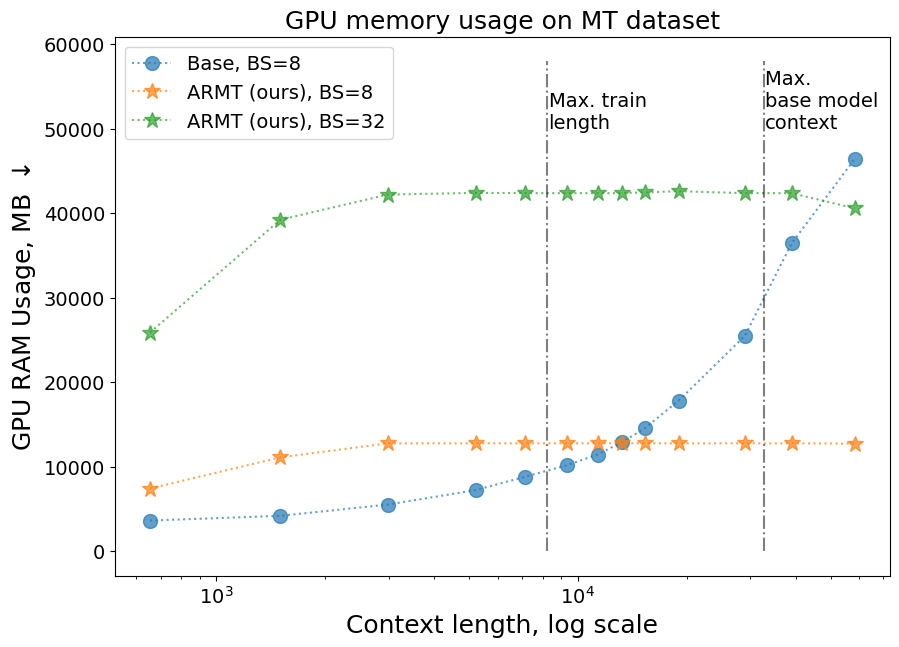

In [178]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_mem"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [50000] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("GPU RAM Usage, MB $\\downarrow$", fontsize=global_fs)
plt.title("GPU memory usage on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14, loc="upper left")
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_mem_usage_gemma_small_all_models_wo_bs1.pdf")

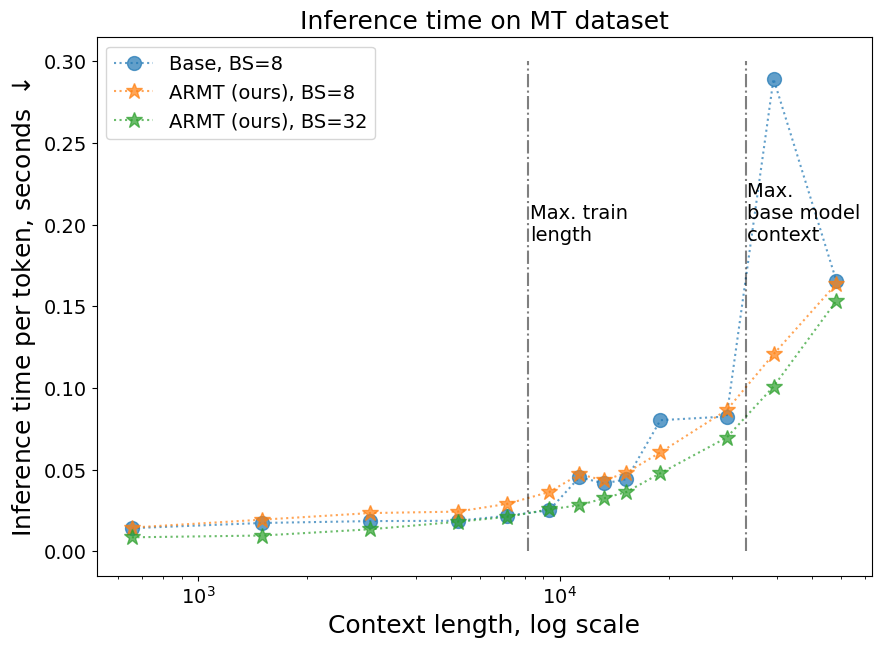

In [182]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_time"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0., ymax=0.3, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0., ymax=0.3, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.2] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("Inference time per token, seconds $\\downarrow$", fontsize=global_fs)
plt.title("Inference time on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_inf_time_gemma_small_all_models_wo_bs1.pdf")

### TIme with FA2

In [243]:
time_fnames = [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs1.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs8.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-9700/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs8.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_50000/checkpoint-9800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs4.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs1.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs8.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs32.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/mem_empty_fa2_time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_override_attn_flash_attention_2_bs64.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/time_qa_evals_mt_0k_64k_600_v2_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_16k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-04_10000/checkpoint-200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_bs4.csv",
]
time_names = [
    "Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    "ARMT-Gemma-3-1B-IT-MT-8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-64",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]

In [244]:
# get times
time_res = {}
buf_fnames = time_fnames
buf_names = time_names
for path, name in zip(buf_fnames, buf_names):
    print(name)
    buf_df = pd.read_csv(path)
    print(len(buf_df))
    if path == buf_fnames[0]:
        time_res["question"] = buf_df["question"]
        time_res["context"] = buf_df["context"]
        time_res["target"] = buf_df["target"]
    time_res[f"{name}_time_base"] = buf_df["time"]
    time_res[f"{name}_answer"] = buf_df["output"]
    time_res[f"{name}_mem"] = buf_df["mem_usage"]
    time_res[f"{name}_ans_len"] = calc_ans_lengths(buf_df, "output", tokenizer)
    time_res[f"{name}_time"] = np.array(time_res[f"{name}_time_base"]) / np.array(time_res[f"{name}_ans_len"])
time_df = pd.DataFrame.from_dict(time_res)
time_df["lens"] = calc_lengths(time_df, tokenizer)

Gemma-3-1B-IT-MT-8k
1300
Gemma-3-1B-IT-MT-8k, batched-8
1300
ARMT-Gemma-3-1B-IT-MT-8k
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched-32
1300
ARMT-Gemma-3-1B-IT-MT-8k, batched-64
1300


In [245]:
time_cols_only_bal_sup = [el for el in time_df.columns if ((("_time" in el and "_rougeLsum" not in el) or "len" in el or "mem" in el) and "_lens" not in el)]
results_time_bal_sup = {}
targs_time = time_df[time_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_time[(targs_time["lens"] > start) & (targs_time["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_time_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [246]:
times_bal_sup = pd.concat(results_time_bal_sup, axis=1)
#times_bal_sup = times_bal_sup.drop("lens")
times_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma-3-1B-IT-MT-8k_time_base,0.471034,0.524791,0.458779,0.539983,0.503727,0.494834,0.506030,0.508336,0.482635,0.491860,0.823905,0.867688,9.088134
Gemma-3-1B-IT-MT-8k_mem,2858.615385,2928.057143,3062.849057,3253.726027,3429.804348,3627.950617,3782.747253,3949.000000,4161.303371,4465.180556,5372.772277,6296.104348,7919.900990
Gemma-3-1B-IT-MT-8k_ans_len,8.500000,9.619048,8.132075,9.410959,8.315217,7.617284,7.373626,6.914894,6.067416,5.673611,10.633663,8.826087,178.574257
Gemma-3-1B-IT-MT-8k_time,0.056639,0.056252,0.057635,0.059399,0.062600,0.066807,0.072054,0.081184,0.084821,0.094808,0.114513,0.152069,0.102093
"Gemma-3-1B-IT-MT-8k, batched-8_time_base",0.105923,0.135230,0.134375,0.146037,0.158744,0.176921,0.267379,0.255527,0.239018,0.278791,0.392554,0.538504,0.795948
"Gemma-3-1B-IT-MT-8k, batched-8_mem",3642.846154,4201.733333,5535.018868,7246.493151,8836.130435,10210.740741,11458.549451,12934.978723,14543.483146,17830.208333,25486.099010,35755.200000,46853.089109
"Gemma-3-1B-IT-MT-8k, batched-8_ans_len",8.538462,9.885714,8.500000,9.178082,8.358696,7.851852,7.934066,11.223404,8.123596,7.979167,7.722772,5.313043,8.118812
"Gemma-3-1B-IT-MT-8k, batched-8_time",0.013991,0.017381,0.018354,0.019104,0.021498,0.024863,0.037473,0.030804,0.033873,0.042194,0.066423,0.163043,0.199931
ARMT-Gemma-3-1B-IT-MT-8k_time_base,0.625810,0.626744,0.667126,0.862197,0.954591,1.058635,1.248730,1.420642,1.532687,1.783597,2.756553,3.157436,4.630750
ARMT-Gemma-3-1B-IT-MT-8k_mem,3136.589744,3711.123810,4220.415094,4220.219178,4220.478261,4220.049383,4220.175824,4220.446809,4220.337079,4220.583333,4220.316832,4220.417391,4220.039604


In [247]:
x=1

In [248]:
import matplotlib.pyplot as plt
import matplotlib as mpl


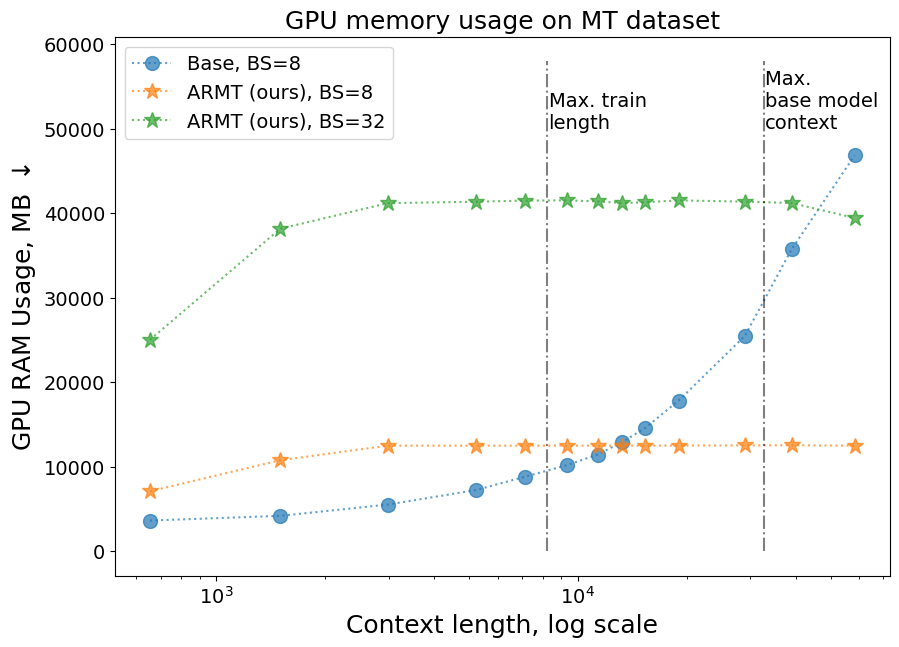

In [231]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_mem"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.3, ymax=58000, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [50000] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("GPU RAM Usage, MB $\\downarrow$", fontsize=global_fs)
plt.title("GPU memory usage on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14, loc="upper left")
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_mem_usage_gemma_small_all_models_flash_attn.pdf")

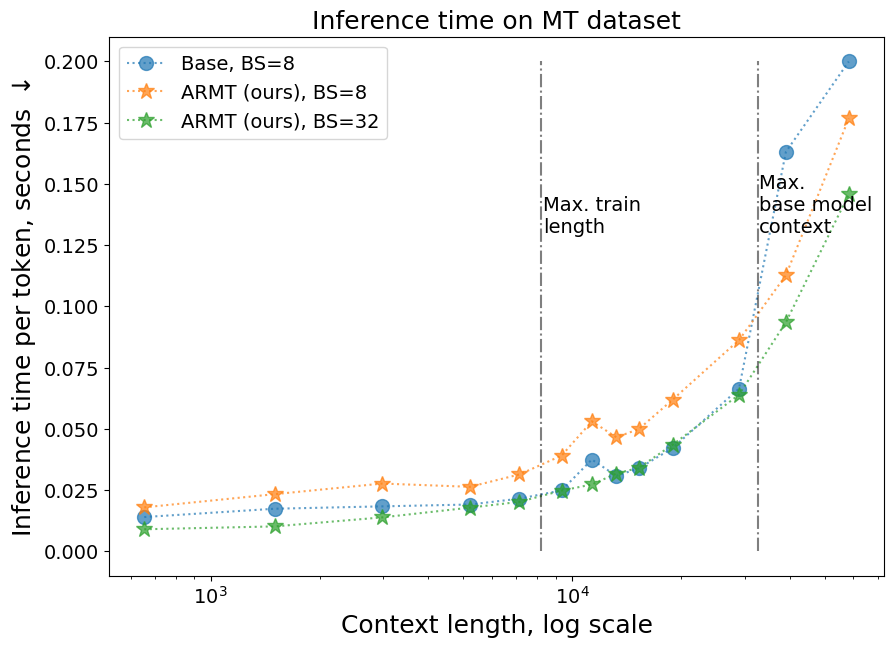

In [234]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*"]
tts_multiplier = [8, 8, 32]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(times_bal_sup.T[f"{key}_time"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
plt.vlines([32*1024], ymin=0., ymax=0.2, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0., ymax=0.2, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.14] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("Inference time per token, seconds $\\downarrow$", fontsize=global_fs)
plt.title("Inference time on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_inf_time_gemma_small_all_models_flash_attn.pdf")

Base, BS=8 [71.4742586  57.53366066 54.48377086 52.34372907 46.51542707 40.22106617
 26.6858541  32.46284039 29.52165966 23.69994647 15.05504927  6.13334778
  5.00172665]
ARMT (ours), BS=8 [55.72724309 42.86927314 36.15184537 37.97983983 31.86472466 25.59412421
 18.84325934 21.47486228 20.04527736 16.13801104 11.59633556  8.87545559
  5.66050697]
ARMT (ours), BS=32 [111.08902301  98.31667894  72.20358764  56.06230292  49.52514314
  40.33634307  36.66394738  31.50350275  29.3476444   22.95766967
  15.64120289  10.69684769   6.86193697]


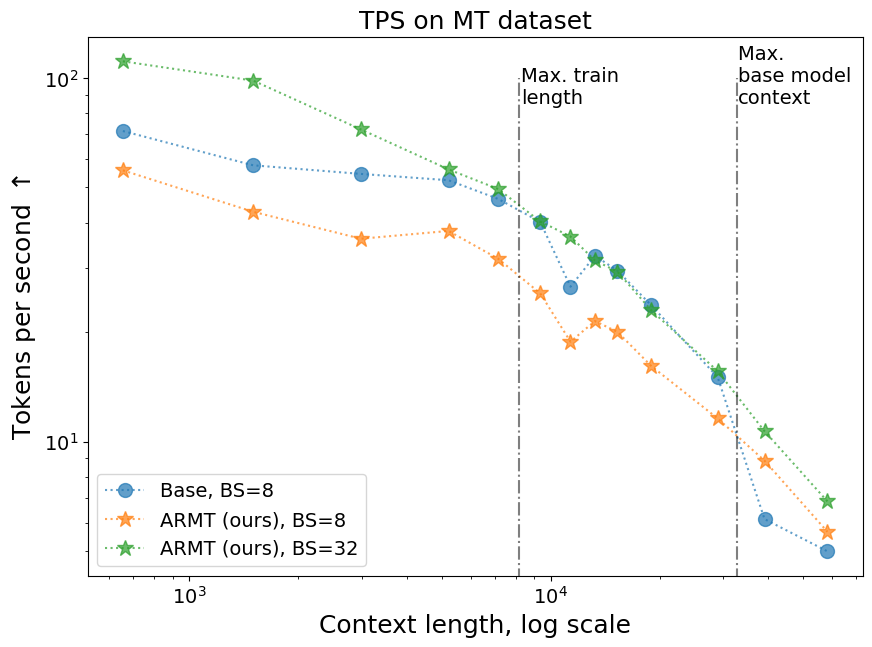

In [253]:

model_keys = [
    #"Gemma-3-1B-IT-MT-8k",
    #"ARMT-Gemma-3-1B-IT-MT-8k",
    "Gemma-3-1B-IT-MT-8k, batched-8",
    #"Gemma-3-1B-IT-MT-8k, batched-4",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched",
    "ARMT-Gemma-3-1B-IT-MT-8k, batched-32",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-64",
    #"ARMT-Gemma-3-1B-IT-MT-8k, batched-4",
]
model_names = [
    #"Base, BS=1",
    #"ARMT (ours), BS=1",
    "Base, BS=8",
    #"Base, batched, 4 bs",
    #"Mamba",
    "ARMT (ours), BS=8",
    "ARMT (ours), BS=32",
    #"ARMT (ours), BS=64",
    #"ARMT (ours), batched, 4 bs",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = times_bal_sup.T["lens"]#np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]
global_fs = 18
#markers = ["o", "v", "s", "D", "*"]
markers = ["o", "*", "o", "*", "*"]
markers = ["o", "*", "*", "*"]
tts_multiplier = [8, 8, 32]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, 1 / np.array(times_bal_sup.T[f"{key}_time"]), marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
    print(name, 1 / np.array(times_bal_sup.T[f"{key}_time"]))
plt.vlines([32*1024], ymin=0., ymax=100, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0., ymax=100, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [85] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Context length, log scale", fontsize=global_fs)
plt.ylabel("Tokens per second $\\uparrow$", fontsize=global_fs)
plt.title("TPS on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
#fig.savefig("../../paper_results/main_res_mt_inf_time_gemma_small_all_models_flash_attn.pdf")

In [27]:
# get times
use_ids = [24, 15,19,22, 83,84,128]
time_res = {}
buf_fnames = [add_fnames[idx] for idx in use_ids]
buf_names = [add_mod_names[idx] for idx in use_ids]
for path, name in zip(buf_fnames, buf_names):
    buf_df = pd.read_csv(path)
    if path == buf_fnames[0]:
        time_res["question"] = buf_df["question"]
        time_res["context"] = buf_df["context"]
        time_res["target"] = buf_df["target"]
    time_res[f"{name}_time_base"] = buf_df["time"]
    time_res[f"{name}_answer"] = buf_df["output"]
    time_res[f"{name}_ans_len"] = calc_ans_lengths(buf_df, "output", tokenizer)
    time_res[f"{name}_time"] = np.array(time_res[f"{name}_time_base"]) / np.array(time_res[f"{name}_ans_len"])
time_df = pd.DataFrame.from_dict(time_res)
time_df["lens"] = calc_lengths(time_df, tokenizer)

In [28]:
time_cols_only_bal_sup = [el for el in time_df.columns if ((("_time" in el and "_rougeLsum" not in el) or "len" in el) and "_lens" not in el)]
results_time_bal_sup = {}
targs_time = time_df[time_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_time[(targs_time["lens"] > start) & (targs_time["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_time_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [29]:
times_bal_sup = pd.concat(results_time_bal_sup, axis=1)
#times_bal_sup = times_bal_sup.drop("lens")
times_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group-1e4-bs64-9700_time_base,0.771766,0.871496,0.773635,0.848160,0.818392,0.823194,0.852830,1.127606,0.932237,0.970605,1.110368,1.086019,1.668436
Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group-1e4-bs64-9700_ans_len,8.538462,9.952381,8.500000,9.178082,8.358696,7.851852,7.934066,11.223404,8.123596,7.951389,7.722772,5.295652,8.118812
Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift-no-group-1e4-bs64-9700_time,0.092574,0.090591,0.093574,0.095596,0.100666,0.107253,0.110779,0.112643,0.120818,0.132021,0.164403,0.275497,0.341465
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-7000_time_base,0.584302,0.623816,0.634672,1.192052,1.205505,2.729400,3.954268,3.709499,4.167283,7.448370,8.711536,11.290483,13.360554
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-7000_ans_len,11.807692,9.723810,8.075472,15.150685,13.706522,44.271605,64.527473,54.521277,65.325843,127.298611,129.871287,173.539130,190.099010
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64-7000_time,0.050438,0.068004,0.082603,0.110978,0.124682,0.140782,0.151849,0.166231,0.163969,0.151684,0.306354,0.413035,0.416702
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_time_base,0.597404,0.608125,0.638393,0.839401,0.939518,1.038274,1.208997,1.372459,1.486218,1.730281,2.804008,3.218764,4.473386
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_ans_len,11.807692,9.276190,7.924528,8.876712,8.336957,7.456790,7.945055,8.702128,7.955056,7.833333,15.346535,10.182609,9.960396
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-1e4-bs64_time,0.051284,0.069430,0.084225,0.104421,0.122966,0.146007,0.163743,0.177144,0.204038,0.238788,0.326307,0.426361,0.663915
ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-3e5-bs64-long-val-from-high-lr-final_time_base,0.603120,0.640426,0.640427,0.831849,1.064682,1.022964,1.180979,1.356184,1.451698,1.798247,2.400984,3.065396,4.403115


## Build all

In [31]:
buf_res = emss.iloc[np.arange(len(emss))].round(3)#,67,68]].round(3)

In [32]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support / sum(support)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support[:5] / sum(support[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support[5:] / sum(support[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support[11:] / sum(support[11:])).sum(axis=1)

In [33]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-128k)"] = cumulative_score_ood_long
buf_res["Full (0k-128k)"] = cumulative_score

In [34]:
buf_res.columns[1:6]

Index(['0k_1k', '1k_2k', '2k_4k', '4k_6k', '6k_8k'], dtype='object')

In [35]:
support[:5]

[78, 105, 106, 73, 92]

In [36]:
s = buf_res.style
for l0 in [0,16,40,44,41,47,52,58,61, 63, 69]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [74,8,46,42,53, 64, 80]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k,65k_98k,98k_131k,In-Domain (0k-8k),OOD (8k-65k),Long-OOD (32k-128k),Full (0k-128k)
0,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift,0.795,0.790,0.774,0.767,0.859,0.852,0.868,0.787,0.764,0.812,0.713,0.591,0.317,0.183,0.262,0.797,0.606,0.345,0.664
1,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.782,0.724,0.689,0.616,0.609,0.506,0.374,0.404,0.337,0.229,0.198,0.139,0.089,0.049,0.034,0.685,0.220,0.077,0.361
2,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.769,0.743,0.708,0.658,0.793,0.765,0.659,0.585,0.596,0.625,0.465,0.417,0.406,0.171,0.248,0.736,0.485,0.314,0.561
3,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.756,0.743,0.736,0.699,0.804,0.753,0.791,0.745,0.685,0.757,0.713,0.765,0.713,0.573,0.759,0.749,0.731,0.716,0.736
4,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain,0.769,0.752,0.708,0.671,0.793,0.753,0.692,0.745,0.629,0.632,0.584,0.530,0.426,0.378,0.166,0.740,0.536,0.359,0.598
5,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain,0.756,0.743,0.708,0.671,0.804,0.790,0.747,0.734,0.640,0.639,0.673,0.609,0.545,0.512,0.414,0.738,0.618,0.513,0.655
6,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain,0.756,0.743,0.736,0.740,0.859,0.827,0.868,0.766,0.697,0.757,0.812,0.791,0.762,0.646,0.821,0.767,0.778,0.767,0.774
7,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain-no-cl,0.808,0.771,0.726,0.726,0.804,0.852,0.857,0.766,0.730,0.799,0.772,0.817,0.772,0.732,0.834,0.766,0.796,0.797,0.787
8,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected,0.782,0.724,0.679,0.397,0.130,0.012,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.551,0.001,0.000,0.168
9,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected,0.756,0.705,0.717,0.699,0.815,0.691,0.747,0.766,0.584,0.604,0.436,0.435,0.485,0.232,0.228,0.738,0.508,0.341,0.578


In [37]:
s = buf_res.style
for l0 in [0,16,40,44,41,47,52,58,61, 63, 69]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [74,8,46,42,53, 64, 80]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k,65k_98k,98k_131k,In-Domain (0k-8k),OOD (8k-65k),Long-OOD (32k-128k),Full (0k-128k)
0,Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15-mask-shift,0.795,0.790,0.774,0.767,0.859,0.852,0.868,0.787,0.764,0.812,0.713,0.591,0.317,0.183,0.262,0.797,0.606,0.345,0.664
1,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.782,0.724,0.689,0.616,0.609,0.506,0.374,0.404,0.337,0.229,0.198,0.139,0.089,0.049,0.034,0.685,0.220,0.077,0.361
2,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.769,0.743,0.708,0.658,0.793,0.765,0.659,0.585,0.596,0.625,0.465,0.417,0.406,0.171,0.248,0.736,0.485,0.314,0.561
3,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars,0.756,0.743,0.736,0.699,0.804,0.753,0.791,0.745,0.685,0.757,0.713,0.765,0.713,0.573,0.759,0.749,0.731,0.716,0.736
4,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain,0.769,0.752,0.708,0.671,0.793,0.753,0.692,0.745,0.629,0.632,0.584,0.530,0.426,0.378,0.166,0.740,0.536,0.359,0.598
5,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain,0.756,0.743,0.708,0.671,0.804,0.790,0.747,0.734,0.640,0.639,0.673,0.609,0.545,0.512,0.414,0.738,0.618,0.513,0.655
6,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain,0.756,0.743,0.736,0.740,0.859,0.827,0.868,0.766,0.697,0.757,0.812,0.791,0.762,0.646,0.821,0.767,0.778,0.767,0.774
7,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-8s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-from-pretrain-no-cl,0.808,0.771,0.726,0.726,0.804,0.852,0.857,0.766,0.730,0.799,0.772,0.817,0.772,0.732,0.834,0.766,0.796,0.797,0.787
8,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-2s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected,0.782,0.724,0.679,0.397,0.130,0.012,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.551,0.001,0.000,0.168
9,ARMT-Gemma3-1b-IT-all-lin-64-128-MT-4s-assist-mask-left-pad-es15_no_sw-mask-shift-no-group-bl-pars-top-5-pre-selected,0.756,0.705,0.717,0.699,0.815,0.691,0.747,0.766,0.584,0.604,0.436,0.435,0.485,0.232,0.228,0.738,0.508,0.341,0.578


## Prepare paper results

In [54]:
buf_res = emss.iloc[[0,1,2,3,4,5,6,7,8,9,10, 11,12,13,14]]

In [55]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support / sum(support)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support[:5] / sum(support[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support[5:] / sum(support[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support[11:] / sum(support[11:])).sum(axis=1)

In [56]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-128k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-128k)"] = cumulative_score_ood_long
buf_res["Full (0k-128k)"] = cumulative_score

In [57]:
new_names = [
    "Gemma-3-1B-IT, MT, 8k",
    "ARMT-Gemma-3-1B-IT, MT, 2k",
    "ARMT-Gemma-3-1B-IT, MT, 4k",
    "ARMT-Gemma-3-1B-IT, MT, 8k",

    "ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained",
    "ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained",

    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-final",

    "ARMT-Gemma-3-1B-IT, MT, 2k, top-5, pre-selected",
    "ARMT-Gemma-3-1B-IT, MT, 4k, top-5, pre-selected",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-5, pre-selected",
    "Mamba-2-1.3B, MT, 8k",
    "Mamba-1.4B, MT, 8k",
    "DeltaNet-1.3B, MT, 8k",
    "xLSTM-1.3B, MT, 8k",
    #"xLSTM-1.3B, MT, 8k, max eval 8k",
]

buf_res["Model"] = new_names

### Best MT res

In [40]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[0,1,2,3,4,5,6,7,8,9,10]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [41]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-final","ARMT-Gemma-3-1B-IT, MT, 2k, top-5, pre-selected","ARMT-Gemma-3-1B-IT, MT, 4k, top-5, pre-selected","ARMT-Gemma-3-1B-IT, MT, 8k, top-5, pre-selected"
0k_1k,0.795,0.782,0.769,0.756,0.769,0.756,0.756,0.808,0.782,0.756,0.756
1k_2k,0.790,0.724,0.743,0.743,0.752,0.743,0.743,0.771,0.724,0.705,0.705
2k_4k,0.774,0.689,0.708,0.736,0.708,0.708,0.736,0.726,0.679,0.717,0.717
4k_6k,0.767,0.616,0.658,0.699,0.671,0.671,0.740,0.726,0.397,0.699,0.712
6k_8k,0.859,0.609,0.793,0.804,0.793,0.804,0.859,0.804,0.130,0.815,0.837
8k_10k,0.852,0.506,0.765,0.753,0.753,0.790,0.827,0.852,0.012,0.691,0.840
10k_12k,0.868,0.374,0.659,0.791,0.692,0.747,0.868,0.857,0.000,0.747,0.857
12k_14k,0.787,0.404,0.585,0.745,0.745,0.734,0.766,0.766,0.000,0.766,0.777
14k_16k,0.764,0.337,0.596,0.685,0.629,0.640,0.697,0.730,0.000,0.584,0.685
16k_24k,0.812,0.229,0.625,0.757,0.632,0.639,0.757,0.799,0.000,0.604,0.812


In [42]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k, from pretrained & ARMT-Gemma-3-1B-IT, MT, 4k, from pretrained & ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained & ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-final & ARMT-Gemma-3-1B-IT, MT, 2k, top-5, pre-selected & ARMT-Gemma-3-1B-IT, MT, 4k, top-5, pre-selected & ARMT-Gemma-3-1B-IT, MT, 8k, top-5, pre-selected \\
\midrule
0k-1k & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{40A000}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{40A000}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{40A000}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.808 & {\cellcolor[HTML]{329900}} \co

### Best MT res, baselines comparison

In [114]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
#buf_res = buf_res.loc[[0,3,6,7,10, 11,12,13,14,15]]
buf_res = buf_res.loc[[0,3,6,7,10, 11,12,13,14]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [115]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-final","ARMT-Gemma-3-1B-IT, MT, 8k, top-5, pre-selected","Mamba-2-1.3B, MT, 8k","Mamba-1.4B, MT, 8k","DeltaNet-1.3B, MT, 8k","xLSTM-1.3B, MT, 8k"
0k_1k,0.795,0.756,0.756,0.808,0.756,0.731,0.821,0.667,0.782
1k_2k,0.790,0.743,0.743,0.771,0.705,0.819,0.810,0.686,0.819
2k_4k,0.774,0.736,0.736,0.726,0.717,0.726,0.764,0.642,0.755
4k_6k,0.767,0.699,0.740,0.726,0.712,0.753,0.836,0.589,0.836
6k_8k,0.859,0.804,0.859,0.804,0.837,0.870,0.880,0.576,0.870
8k_10k,0.852,0.753,0.827,0.852,0.840,0.815,0.889,0.444,0.864
10k_12k,0.868,0.791,0.868,0.857,0.857,0.868,0.868,0.110,0.890
12k_14k,0.787,0.745,0.766,0.766,0.777,0.766,0.787,0.043,0.819
14k_16k,0.764,0.685,0.697,0.730,0.685,0.719,0.753,0.034,0.742
16k_24k,0.812,0.757,0.757,0.799,0.812,0.812,0.847,0.007,0.819


In [58]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{54AA00}} \color[HTML]{F1F1F1} 0.724 & {\cellcolor[HTML]{5AAD00}} \color[HTML]{F1F1F1} 0.714 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.743 \\
2k-4k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{369B00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{68B400}} \color[HTML]{F1F1F1} 0.689 & {\cellcolor[HTML]{64B200}} \color[HTML]{F1F1F1} 

### Best MT res, assoc. ablation

In [177]:
buf_res = buf_res.loc[[24, 22, 27,28,29,30,59,60]]
#buf_res = buf_res.loc[[24, 22 ]+ list(range(31, 31+26))]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [178]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, 0-6 layers removed","ARMT-Gemma-3-1B-IT, MT, 8k, 7-12 layers removed","ARMT-Gemma-3-1B-IT, MT, 8k, 13-18 layers removed","ARMT-Gemma-3-1B-IT, MT, 8k, 19-25 layers removed","ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used"
0k_1k,0.795,0.756,0.756,0.756,0.756,0.756,0.756,0.756
1k_2k,0.790,0.743,0.733,0.743,0.571,0.676,0.590,0.724
2k_4k,0.774,0.736,0.736,0.726,0.443,0.717,0.594,0.708
4k_6k,0.767,0.699,0.699,0.699,0.329,0.671,0.521,0.712
6k_8k,0.859,0.804,0.815,0.804,0.315,0.739,0.598,0.793
8k_10k,0.852,0.753,0.753,0.765,0.395,0.716,0.531,0.765
10k_12k,0.868,0.791,0.780,0.791,0.341,0.736,0.505,0.758
12k_14k,0.787,0.745,0.766,0.766,0.277,0.809,0.457,0.755
14k_16k,0.764,0.685,0.674,0.674,0.337,0.708,0.472,0.663
16k_24k,0.812,0.757,0.750,0.764,0.306,0.722,0.458,0.729


In [179]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, 0-6 layers removed & ARMT-Gemma-3-1B-IT, MT, 8k, 7-12 layers removed & ARMT-Gemma-3-1B-IT, MT, 8k, 13-18 layers removed & ARMT-Gemma-3-1B-IT, MT, 8k, 19-25 layers removed & ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{58AC00}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{3E9F00}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{62B100}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{6AB

### Best MT res, assoc. ablation, all layers

In [192]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
#buf_res = buf_res.loc[[24, 22 ]+ list(range(31, 31+13))]
buf_res = buf_res.loc[[24, 22 ]+ list(range(31+13, 31+26))]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [193]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k",W/o layer 13,W/o layer 14,W/o layer 15,W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25
0k_1k,0.795,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756,0.756
1k_2k,0.790,0.743,0.733,0.610,0.743,0.743,0.743,0.695,0.695,0.743,0.743,0.743,0.752,0.743,0.733
2k_4k,0.774,0.736,0.736,0.491,0.736,0.736,0.736,0.726,0.736,0.736,0.736,0.736,0.726,0.736,0.726
4k_6k,0.767,0.699,0.699,0.384,0.699,0.699,0.699,0.671,0.712,0.699,0.699,0.699,0.685,0.699,0.671
6k_8k,0.859,0.804,0.815,0.370,0.804,0.804,0.804,0.772,0.793,0.804,0.804,0.804,0.793,0.804,0.783
8k_10k,0.852,0.753,0.741,0.407,0.753,0.753,0.753,0.716,0.765,0.753,0.753,0.753,0.765,0.753,0.741
10k_12k,0.868,0.791,0.791,0.330,0.791,0.791,0.791,0.736,0.780,0.791,0.791,0.791,0.769,0.769,0.769
12k_14k,0.787,0.745,0.734,0.255,0.745,0.745,0.745,0.660,0.755,0.745,0.745,0.745,0.755,0.755,0.734
14k_16k,0.764,0.685,0.685,0.360,0.685,0.685,0.685,0.618,0.697,0.685,0.685,0.685,0.719,0.697,0.697
16k_24k,0.812,0.757,0.757,0.333,0.757,0.757,0.757,0.715,0.743,0.757,0.764,0.757,0.764,0.764,0.750


In [194]:
# top-1 - 14
# top-4 - 14, 18, 23, 19/12/9 (now 8,13,14,18) || after fix - 14, 18, 5/19/25

In [195]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccccccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & W/o layer 13 & W/o layer 14 & W/o layer 15 & W/o layer 16 & W/o layer 17 & W/o layer 18 & W/o layer 19 & W/o layer 20 & W/o layer 21 & W/o layer 22 & W/o layer 23 & W/o layer 24 & W/o layer 25 \\
\midrule
0k-1k & {\cellcolor[HTML]{3C9E00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor

### Best MT res, assoc. ablation, top-layers

In [121]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
buf_res = buf_res.loc[[24, 22 ]+ [59,60]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [122]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used"
0k_1k,0.795,0.756,0.756,0.744
1k_2k,0.790,0.743,0.590,0.638
2k_4k,0.774,0.736,0.594,0.698
4k_6k,0.767,0.699,0.521,0.671
6k_8k,0.859,0.804,0.598,0.750
8k_10k,0.852,0.753,0.531,0.691
10k_12k,0.868,0.791,0.505,0.747
12k_14k,0.787,0.745,0.457,0.734
14k_16k,0.764,0.685,0.472,0.652
16k_24k,0.812,0.757,0.458,0.701


In [80]:
# top-1 - 14
# top-4 - 14, 18, 23, 19/12/9 (now 8,13,14,18)

In [81]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{68B400}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.744 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.744 \\
1k-2k & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{74BA00}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{FFFC00}} \color[HTML]{000000} 0.590 & {\cellcolor[HTML]{D4EA00}} \color[HTML]{000000} 0.638 \\
2k-4k & {\cellcolor[HTML]{56AB00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{7ABD00}} \color[HTML]{F1F1F1} 0.736 & {\cellcolor[HTML]{FFE600}} \color[HTML]{000000} 0.566 & {\cellcolor[HTML]{9CCE00}} \color[HTML]{000000} 0.698 \\
4k-6k & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.767 & {\cellcolor[HTML]{9CCE00}} \color[HTML]{

### Best MT res, assoc. ablation, top-layers + trained

In [39]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
buf_res = buf_res.loc[[24, 22 ]+ [59,60] + [61,62, 67]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [40]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, MT, 2k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 4k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained"
0k_1k,0.795,0.756,0.756,0.756,0.782,0.782,0.756
1k_2k,0.790,0.743,0.590,0.724,0.714,0.686,0.714
2k_4k,0.774,0.736,0.594,0.708,0.660,0.717,0.736
4k_6k,0.767,0.699,0.521,0.712,0.452,0.699,0.699
6k_8k,0.859,0.804,0.598,0.793,0.185,0.793,0.815
8k_10k,0.852,0.753,0.531,0.765,0.099,0.790,0.827
10k_12k,0.868,0.791,0.505,0.758,0.022,0.747,0.802
12k_14k,0.787,0.745,0.457,0.755,0.032,0.691,0.777
14k_16k,0.764,0.685,0.472,0.663,0.011,0.584,0.708
16k_24k,0.812,0.757,0.458,0.729,0.000,0.542,0.757


In [276]:
# top-1 - 14
# top-4 - 14, 18, 23, 19/12/9 (now 8,13,14,18)

In [81]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, 14th layer used & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{68B400}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.744 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.744 \\
1k-2k & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{74BA00}} \color[HTML]{F1F1F1} 0.743 & {\cellcolor[HTML]{FFFC00}} \color[HTML]{000000} 0.590 & {\cellcolor[HTML]{D4EA00}} \color[HTML]{000000} 0.638 \\
2k-4k & {\cellcolor[HTML]{56AB00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{7ABD00}} \color[HTML]{F1F1F1} 0.736 & {\cellcolor[HTML]{FFE600}} \color[HTML]{000000} 0.566 & {\cellcolor[HTML]{9CCE00}} \color[HTML]{000000} 0.698 \\
4k-6k & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.767 & {\cellcolor[HTML]{9CCE00}} \color[HTML]{

### Best MT res, assoc. ablation, top-layers + trained top-N universal

In [74]:
#buf_res = buf_res.loc[[24, 22, 27,28,29,30 ]]
buf_res = buf_res.loc[[24, 15,19,22 ]+ [60] + [61,62, 67, 68,69,70]]
#buf_res = buf_res.loc[[24, 22 ]+ [60] + [67, 70]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [75]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, MT, 2k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 4k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained","ARMT-Gemma-3-1B-IT, MT, 2k, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 4k, top-5 layers trained","ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained"
0k_1k,0.795,0.782,0.782,0.756,0.756,0.782,0.782,0.756,0.782,0.756,0.756
1k_2k,0.790,0.724,0.714,0.743,0.724,0.714,0.686,0.714,0.724,0.705,0.705
2k_4k,0.774,0.689,0.698,0.736,0.708,0.660,0.717,0.736,0.679,0.717,0.717
4k_6k,0.767,0.616,0.644,0.699,0.712,0.452,0.699,0.699,0.397,0.699,0.712
6k_8k,0.859,0.609,0.717,0.804,0.793,0.185,0.793,0.815,0.130,0.815,0.837
8k_10k,0.852,0.506,0.753,0.753,0.765,0.099,0.790,0.827,0.012,0.691,0.840
10k_12k,0.868,0.374,0.670,0.791,0.758,0.022,0.747,0.802,0.000,0.747,0.857
12k_14k,0.787,0.404,0.702,0.745,0.755,0.032,0.691,0.777,0.000,0.766,0.777
14k_16k,0.764,0.337,0.640,0.685,0.663,0.011,0.584,0.708,0.000,0.584,0.685
16k_24k,0.812,0.229,0.646,0.757,0.729,0.000,0.542,0.757,0.000,0.604,0.812


In [62]:
# top-1 - 14
# top-4 - 14, 18, 23, 19/12/9 (now 8,13,14,18)

In [76]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used & ARMT-Gemma-3-1B-IT, MT, 2k, top-4 layers trained & ARMT-Gemma-3-1B-IT, MT, 4k, top-4 layers trained & ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained & ARMT-Gemma-3-1B-IT, MT, 2k, top-5 layers trained & ARMT-Gemma-3-1B-IT, MT, 4k, top-5 layers trained & ARMT-Gemma-3-1B-IT, MT, 8k, top-5 layers trained \\
\midrule
0k-1k & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 & {\cellcolor[HTML]{3299

### Best MT res + MT script version

In [232]:
buf_res = buf_res.loc[[26, 24,15,19, 22, 63,64,65]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [233]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 2k","ARMT-Gemma-3-1B-IT, MT, 4k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT-script-version, 2k","ARMT-Gemma-3-1B-IT, MT-script-version, 4k","ARMT-Gemma-3-1B-IT, MT-script-version, 8k"
0k_1k,0.000,0.795,0.782,0.782,0.756,0.782,0.744,0.756
1k_2k,0.000,0.790,0.724,0.714,0.743,0.705,0.705,0.705
2k_4k,0.000,0.774,0.689,0.698,0.736,0.708,0.708,0.698
4k_6k,0.000,0.767,0.616,0.644,0.699,0.616,0.671,0.712
6k_8k,0.000,0.859,0.609,0.717,0.804,0.457,0.783,0.826
8k_10k,0.000,0.852,0.506,0.753,0.753,0.247,0.716,0.815
10k_12k,0.011,0.868,0.374,0.670,0.791,0.055,0.637,0.868
12k_14k,0.000,0.787,0.404,0.702,0.745,0.032,0.670,0.745
14k_16k,0.000,0.764,0.337,0.640,0.685,0.034,0.528,0.663
16k_24k,0.000,0.812,0.229,0.646,0.757,0.007,0.451,0.757


In [58]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 2k & ARMT-Gemma-3-1B-IT, MT, 4k & ARMT-Gemma-3-1B-IT, MT, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.782 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F1F1} 0.756 \\
1k-2k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{54AA00}} \color[HTML]{F1F1F1} 0.724 & {\cellcolor[HTML]{5AAD00}} \color[HTML]{F1F1F1} 0.714 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.743 \\
2k-4k & {\cellcolor[HTML]{FF0000}} \color[HTML]{F1F1F1} 0.000 & {\cellcolor[HTML]{369B00}} \color[HTML]{F1F1F1} 0.774 & {\cellcolor[HTML]{68B400}} \color[HTML]{F1F1F1} 0.689 & {\cellcolor[HTML]{64B200}} \color[HTML]{F1F1F1} 

### Main MT res for plot

In [128]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
#buf_res = buf_res.loc[[26, 24, 71,72,73 ,15,19, 22, 60,67,70, 85, 128, 187]]
buf_res = buf_res.loc[[0,3,6,7,10, 11,12,13,14]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [129]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-final","ARMT-Gemma-3-1B-IT, MT, 8k, top-5, pre-selected","Mamba-2-1.3B, MT, 8k","Mamba-1.4B, MT, 8k","DeltaNet-1.3B, MT, 8k","xLSTM-1.3B, MT, 8k"
0k_1k,0.795,0.756,0.756,0.808,0.756,0.731,0.821,0.667,0.782
1k_2k,0.790,0.743,0.743,0.771,0.705,0.819,0.810,0.686,0.819
2k_4k,0.774,0.736,0.736,0.726,0.717,0.726,0.764,0.642,0.755
4k_6k,0.767,0.699,0.740,0.726,0.712,0.753,0.836,0.589,0.836
6k_8k,0.859,0.804,0.859,0.804,0.837,0.870,0.880,0.576,0.870
8k_10k,0.852,0.753,0.827,0.852,0.840,0.815,0.889,0.444,0.864
10k_12k,0.868,0.791,0.868,0.857,0.857,0.868,0.868,0.110,0.890
12k_14k,0.787,0.745,0.766,0.766,0.777,0.766,0.787,0.043,0.819
14k_16k,0.764,0.685,0.697,0.730,0.685,0.719,0.753,0.034,0.742
16k_24k,0.812,0.757,0.757,0.799,0.812,0.812,0.847,0.007,0.819


In [130]:
import matplotlib.pyplot as plt
import matplotlib as mpl


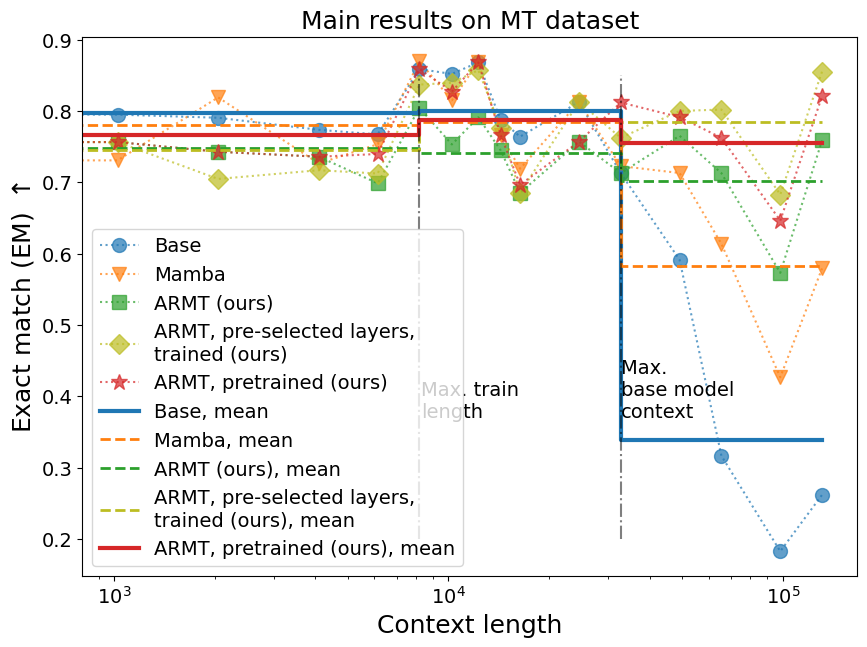

In [135]:

model_keys = [
    "Gemma-3-1B-IT, MT, 8k",
    "Mamba-2-1.3B, MT, 8k",#"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT, MT, 8k",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-5, pre-selected",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v3",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained",
]
model_names = [
    "Base",
    "Mamba",
    "ARMT (ours)",
    #"ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    "ARMT, pre-selected layers, \ntrained (ours)",
    "ARMT, pretrained (ours)",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64, 96, 128]) * 1024
main_ids = [0, 4]

markers = ["o", "v", "s", "D", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 128]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,15], [11,15]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([32*1024], ymin=0.2, ymax=0.85, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.2, ymax=0.85, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.38] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("Exact match (EM) $\\uparrow$", fontsize=global_fs)
plt.title("Main results on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_gemma_new_mamba_128k.pdf")

### Main MT res for plot, poster

In [58]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
#buf_res = buf_res.loc[[26, 24, 71,72,73 ,15,19, 22, 60,67,70, 85, 128, 187]]
buf_res = buf_res.loc[[0,3,6,7,10, 11,12,13,14]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [59]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-no-cl-final","ARMT-Gemma-3-1B-IT, MT, 8k, top-5, pre-selected","Mamba-2-1.3B, MT, 8k","Mamba-1.4B, MT, 8k","DeltaNet-1.3B, MT, 8k","xLSTM-1.3B, MT, 8k"
0k_1k,0.795,0.756,0.756,0.808,0.756,0.731,0.821,0.667,0.782
1k_2k,0.790,0.743,0.743,0.771,0.705,0.819,0.810,0.686,0.819
2k_4k,0.774,0.736,0.736,0.726,0.717,0.726,0.764,0.642,0.755
4k_6k,0.767,0.699,0.740,0.726,0.712,0.753,0.836,0.589,0.836
6k_8k,0.859,0.804,0.859,0.804,0.837,0.870,0.880,0.576,0.870
8k_10k,0.852,0.753,0.827,0.852,0.840,0.815,0.889,0.444,0.864
10k_12k,0.868,0.791,0.868,0.857,0.857,0.868,0.868,0.110,0.890
12k_14k,0.787,0.745,0.766,0.766,0.777,0.766,0.787,0.043,0.819
14k_16k,0.764,0.685,0.697,0.730,0.685,0.719,0.753,0.034,0.742
16k_24k,0.812,0.757,0.757,0.799,0.812,0.812,0.847,0.007,0.819


In [60]:
import matplotlib.pyplot as plt
import matplotlib as mpl


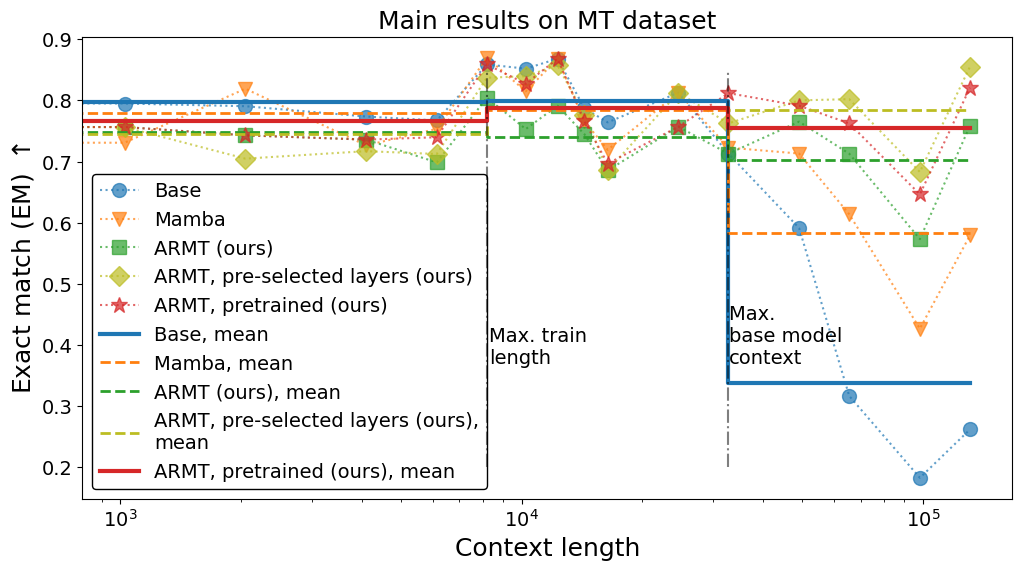

In [63]:

model_keys = [
    "Gemma-3-1B-IT, MT, 8k",
    "Mamba-2-1.3B, MT, 8k",#"Mamba-1.3B gen64, MT, 8k",
    "ARMT-Gemma-3-1B-IT, MT, 8k",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    "ARMT-Gemma-3-1B-IT, MT, 8k, top-5, pre-selected",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-prelim-v3",
    "ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained",
]
model_names = [
    "Base",
    "Mamba",
    "ARMT (ours)",
    #"ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    "ARMT, pre-selected layers (ours)",
    "ARMT, pretrained (ours)",
]
fig = plt.figure(figsize=(12,6))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64, 96, 128]) * 1024
main_ids = [0, 4]

markers = ["o", "v", "s", "D", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 128]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,15], [11,15]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    if "pre-selected layers" in name:
        plt.plot(new_x, new_y, label=name+",\nmean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
    else:
        plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([32*1024], ymin=0.2, ymax=0.85, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.2, ymax=0.85, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.38] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("Exact match (EM) $\\uparrow$", fontsize=global_fs)
plt.title("Main results on MT dataset", fontsize=global_fs)
plt.legend(fontsize=14)

legend = plt.legend(loc="lower left", fontsize=14, edgecolor="black")
legend.get_frame().set_alpha(None)
legend.get_frame().set_facecolor((0, 0, 1, 0.001))
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_mt_gemma_new_mamba_128k_poster.pdf", transparent=True)

### Best MT res, baselines comparison

In [431]:
#buf_res = buf_res.loc[[26, 24,15,19, 22, ]]
buf_res = buf_res.loc[[24, 22, 128, 203,196,198, 187]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [432]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k","ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final","Mamba-1.4B best, MT, 8k","Mamba-2-1.3B best, MT, 8k","DeltaNet-1.3B best, MT, 8k","xLSTM-1.3B, MT, 8k"
0k_1k,0.795,0.756,0.756,0.846,0.795,0.769,0.769
1k_2k,0.790,0.743,0.743,0.857,0.886,0.819,0.800
2k_4k,0.774,0.736,0.736,0.802,0.802,0.726,0.755
4k_6k,0.767,0.699,0.740,0.836,0.781,0.726,0.822
6k_8k,0.859,0.804,0.859,0.902,0.902,0.891,0.870
8k_10k,0.852,0.753,0.827,0.877,0.827,0.864,0.864
10k_12k,0.868,0.791,0.868,0.879,0.890,0.846,0.890
12k_14k,0.787,0.745,0.766,0.777,0.766,0.755,0.819
14k_16k,0.764,0.685,0.697,0.764,0.764,0.708,0.742
16k_24k,0.812,0.757,0.757,0.882,0.833,0.757,0.819


In [389]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccc}
\toprule
Model & Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k & ARMT-Gemma-3-1B-IT, MT, 8k, from pretrained-final & Mamba-1.4B best, MT, 8k & Mamba-2-1.3B best, MT, 8k & DeltaNet-1.3B best, MT, 8k & xLSTM-1.3B, MT, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{7EBF00}} \color[HTML]{000000} 0.756 & {\cellcolor[HTML]{7EBF00}} \color[HTML]{000000} 0.756 & {\cellcolor[HTML]{309800}} \color[HTML]{F1F1F1} 0.846 & {\cellcolor[HTML]{5CAE00}} \color[HTML]{F1F1F1} 0.795 & {\cellcolor[HTML]{74BA00}} \color[HTML]{F1F1F1} 0.769 & {\cellcolor[HTML]{74BA00}} \color[HTML]{F1F1F1} 0.769 \\
1k-2k & {\cellcolor[HTML]{62B100}} \color[HTML]{F1F1F1} 0.790 & {\cellcolor[HTML]{8AC500}} \color[HTML]{000000} 0.743 & {\cellcolor[HTML]{8AC500}} \color[HTML]{000000} 0.743 & {\cellcolor[HTML]{269300}} \color[HTML]{F1F1F1} 0.857 & {\cellcolor[HTML]{0E8700}} \color[HTML]{F1F1F1} 0.886 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0